In [1]:

# QUESTION 1: DESCRIPTIVE ANALYSIS
# World Bank Global Population Dataset

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the World Bank Population Dataset

df = pd.read_csv("POP.csv")

# Display the first 5 rows
df.head()


,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ranking,NaN,Economy,(thousands),NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,IND,1,NaN,India,"1,417,173",NaN


In [3]:

# Inspect the structure of the population dataset

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

# Display the first 20 rows
display(df.head(20))

Dataset shape:
(328, 6)

Column names:
['Unnamed: 0', 'Population 2022', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']

Data types:
Unnamed: 0             str
Population 2022        str
Unnamed: 2         float64
Unnamed: 3             str
Unnamed: 4             str
Unnamed: 5             str
dtype: object

Missing values:
Unnamed: 0          99
Population 2022    108
Unnamed: 2         328
Unnamed: 3          98
Unnamed: 4          98
Unnamed: 5         326
dtype: int64

Duplicate rows:
95


,Unnamed: 0,Population 2022,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Ranking,NaN,Economy,(thousands),NaN
3,NaN,NaN,NaN,NaN,NaN,NaN
4,IND,1,NaN,India,"1,417,173",NaN
5,CHN,2,NaN,China,"1,412,175",NaN
6,USA,3,NaN,United States,"333,288",NaN
7,IDN,4,NaN,Indonesia,"275,501",NaN
8,PAK,5,NaN,Pakistan,"235,825",NaN
9,NGA,6,NaN,Nigeria,"218,541",NaN


In [4]:

# Create a copy of the original dataset
pop_clean = df.copy()

# Remove completely empty columns
pop_clean = pop_clean.dropna(axis=1, how='all')

# Remove completely empty rows
pop_clean = pop_clean.dropna(axis=0, how='all')

# Check the remaining data
print("Shape after removing empty rows and columns:")
print(pop_clean.shape)

display(pop_clean.head(15))

Shape after removing empty rows and columns:
(232, 5)


,Unnamed: 0,Population 2022,Unnamed: 3,Unnamed: 4,Unnamed: 5
2,NaN,Ranking,Economy,(thousands),NaN
4,IND,1,India,"1,417,173",NaN
5,CHN,2,China,"1,412,175",NaN
6,USA,3,United States,"333,288",NaN
7,IDN,4,Indonesia,"275,501",NaN
8,PAK,5,Pakistan,"235,825",NaN
9,NGA,6,Nigeria,"218,541",NaN
10,BRA,7,Brazil,"215,313",NaN
11,BGD,8,Bangladesh,"171,186",NaN
12,RUS,9,Russian Federation,"143,556",NaN


In [5]:

# Rename columns for clarity
pop_clean = pop_clean.rename(columns={
    'Unnamed: 0': 'Country_Code',
    'Population 2022': 'Ranking',
    'Unnamed: 3': 'Country',
    'Unnamed: 4': 'Population',
    'Unnamed: 5': 'Extra'
})

# Display the first 10 rows
pop_clean.head(10)


,Country_Code,Ranking,Country,Population,Extra
2,NaN,Ranking,Economy,(thousands),NaN
4,IND,1,India,"1,417,173",NaN
5,CHN,2,China,"1,412,175",NaN
6,USA,3,United States,"333,288",NaN
7,IDN,4,Indonesia,"275,501",NaN
8,PAK,5,Pakistan,"235,825",NaN
9,NGA,6,Nigeria,"218,541",NaN
10,BRA,7,Brazil,"215,313",NaN
11,BGD,8,Bangladesh,"171,186",NaN
12,RUS,9,Russian Federation,"143,556",NaN


In [6]:

# Remove the extra column
pop_clean = pop_clean.drop(columns=['Extra'])

# Remove the row containing headings
pop_clean = pop_clean[
    pop_clean['Ranking'] != 'Ranking'
]

# Display the cleaned data
pop_clean.head()


,Country_Code,Ranking,Country,Population
4,IND,1,India,"1,417,173"
5,CHN,2,China,"1,412,175"
6,USA,3,United States,"333,288"
7,IDN,4,Indonesia,"275,501"
8,PAK,5,Pakistan,"235,825"


In [7]:

# Remove commas from population figures
pop_clean['Population'] = pop_clean['Population'].str.replace(',', '')

# Convert population to numeric
pop_clean['Population'] = pd.to_numeric(
    pop_clean['Population'], errors='coerce'
)

# Convert ranking to numeric
pop_clean['Ranking'] = pd.to_numeric(
    pop_clean['Ranking'], errors='coerce'
)

# Check data types
pop_clean.dtypes


Country_Code        str
Ranking         float64
Country             str
Population      float64
dtype: object

In [8]:

# Check missing values
print(pop_clean.isnull().sum())

# Check duplicates
print("Duplicates:", pop_clean.duplicated().sum())

# Display cleaned dataset
pop_clean.head(10)


Country_Code     2
Ranking         14
Country          2
Population       2
dtype: int64
Duplicates: 1


,Country_Code,Ranking,Country,Population
4,IND,1.0,India,1417173.0
5,CHN,2.0,China,1412175.0
6,USA,3.0,United States,333288.0
7,IDN,4.0,Indonesia,275501.0
8,PAK,5.0,Pakistan,235825.0
9,NGA,6.0,Nigeria,218541.0
10,BRA,7.0,Brazil,215313.0
11,BGD,8.0,Bangladesh,171186.0
12,RUS,9.0,Russian Federation,143556.0
13,MEX,10.0,Mexico,127504.0


In [9]:

# Display rows with missing values
pop_clean[pop_clean.isnull().any(axis=1)]

,Country_Code,Ranking,Country,Population
223,WLD,NaN,World,7951150.0
225,EAS,NaN,East Asia & Pacific,2375143.0
226,ECS,NaN,Europe & Central Asia,920631.0
227,LCN,NaN,Latin America & Caribbean,659311.0
228,MEA,NaN,Middle East & North Africa,493265.0
229,NAC,NaN,North America,372281.0
230,SAS,NaN,South Asia,1919348.0
231,SSF,NaN,Sub-Saharan Africa,1211170.0
232,LIC,NaN,Low income,703728.0
233,LMC,NaN,Lower middle income,3190013.0


In [10]:

# Remove duplicate rows
pop_clean = pop_clean.drop_duplicates()

# Check remaining duplicates
print("Duplicates:", pop_clean.duplicated().sum())

Duplicates: 0


In [11]:

# Check dataset after removing duplicates
print("Dataset shape:", pop_clean.shape)

print("\nMissing values:")
print(pop_clean.isnull().sum())

pop_clean.head()

Dataset shape: (230, 4)

Missing values:
Country_Code     1
Ranking         13
Country          1
Population       1
dtype: int64


,Country_Code,Ranking,Country,Population
4,IND,1.0,India,1417173.0
5,CHN,2.0,China,1412175.0
6,USA,3.0,United States,333288.0
7,IDN,4.0,Indonesia,275501.0
8,PAK,5.0,Pakistan,235825.0


In [12]:

# Remove rows without country rankings
pop_clean = pop_clean.dropna(subset=['Ranking'])

# Remove duplicate records
pop_clean = pop_clean.drop_duplicates()

# Check remaining missing values
print(pop_clean.isnull().sum())

# Check duplicates
print("Duplicates:", pop_clean.duplicated().sum())

# Check dataset size
print("Dataset shape:", pop_clean.shape)

Country_Code    0
Ranking         0
Country         0
Population      0
dtype: int64
Duplicates: 0
Dataset shape: (217, 4)


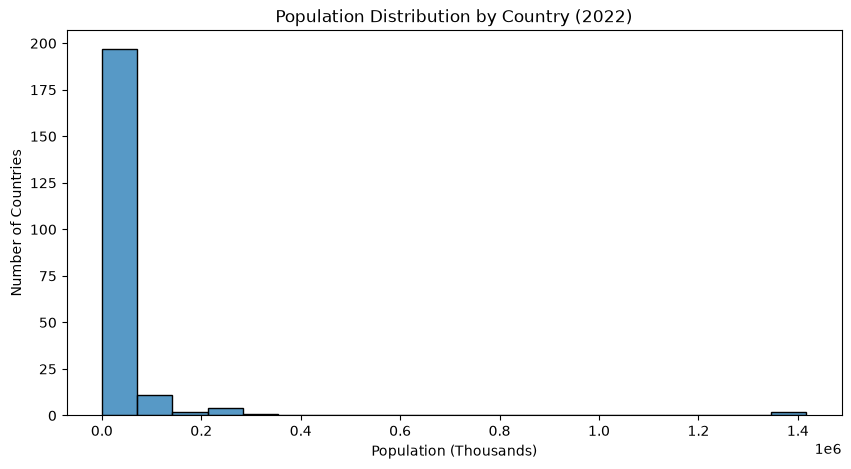

In [13]:

# Histogram of population distribution

plt.figure(figsize=(10, 5))

sns.histplot(data=pop_clean, x='Population', bins=20)

plt.title('Population Distribution by Country (2022)')
plt.xlabel('Population (Thousands)')
plt.ylabel('Number of Countries')

plt.show()


**Interpretation: Population Distribution by Country (2022)**

The histogram shows that population is unevenly distributed across countries. Most countries have relatively small populations, while a few countries have very large populations. The distribution is positively skewed, with most observations concentrated on the left side of the graph. This indicates that a small number of countries account for a substantial share of the world's population.

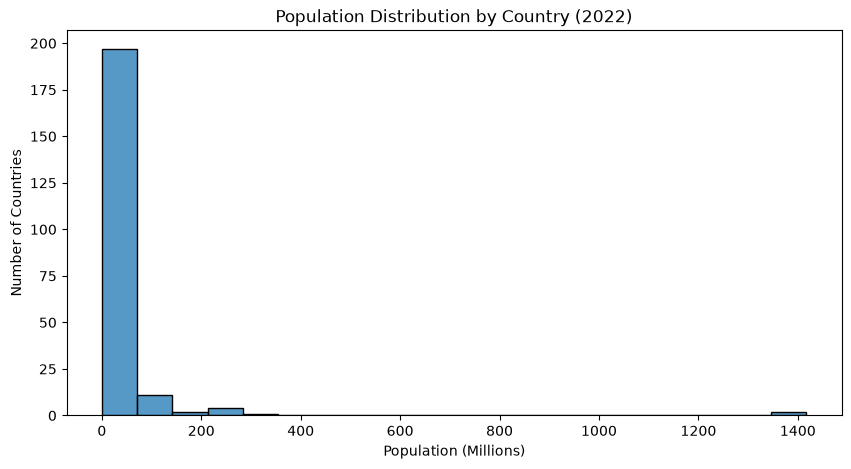

In [14]:

# Convert population from thousands to millions
pop_clean['Population_Millions'] = pop_clean['Population'] / 1000

# Plot population distribution
plt.figure(figsize=(10, 5))

sns.histplot(data=pop_clean, x='Population_Millions', bins=20)

plt.title('Population Distribution by Country (2022)')
plt.xlabel('Population (Millions)')
plt.ylabel('Number of Countries')

plt.show()


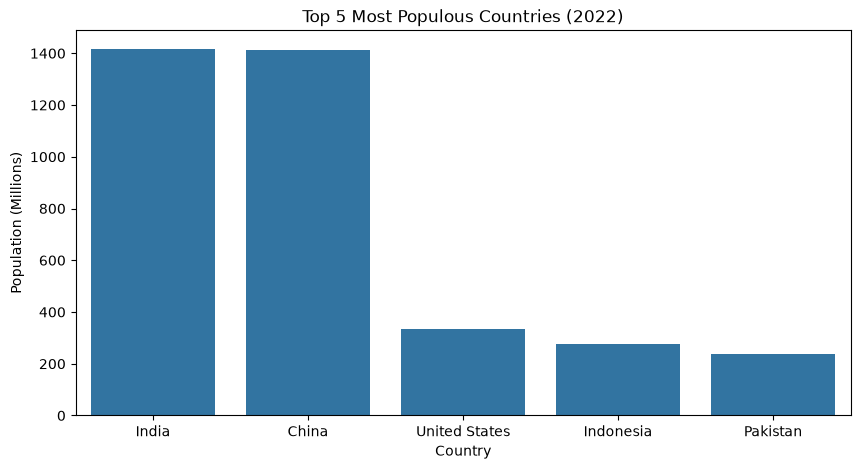

In [15]:

# Select the top 5 most populous countries
top5 = pop_clean.nlargest(5, 'Population')

# Create a bar chart
plt.figure(figsize=(10, 5))

sns.barplot(data=top5, x='Country', y='Population_Millions')

plt.title('Top 5 Most Populous Countries (2022)')
plt.xlabel('Country')
plt.ylabel('Population (Millions)')

plt.show()

**Interpretation: Top Five Most Populous Countries (2022)**

The bar chart shows that India had the highest population in 2022, with approximately 1.42 billion people, closely followed by China at 1.41 billion. The United States ranked third with approximately 333 million people, followed by Indonesia with 276 million and Pakistan with 236 million.

The results show a significant population difference between India and China and the remaining three countries. This indicates that population is unevenly distributed among the world's most populous countries.

### Dataset Limitations and Additional Data Collection

During the initial data exploration, I observed that the provided population dataset contained population statistics for 2022 only. However, the assessment required an analysis of population trends between 2000 and 2020, as well as a correlation analysis between GDP and population.

Since the original dataset did not contain the required historical population and GDP information, I obtained additional data from the official World Bank database to complete the analysis.

The additional data was used to examine population growth trends for the five most populous countries and investigate the relationship between GDP and population.

This approach allowed me to address the limitations of the original dataset while meeting the assessment objectives.

In [16]:

import pandas as pd
import os

# Folder containing the World Bank dataset
folder = r"C:\Users\Tobias\Downloads\API_SP.POP.TOTL_DS2_en_csv_v2_5254"

# Check files inside the folder
print(os.listdir(folder))

['API_SP.POP.TOTL_DS2_en_csv_v2_5254.csv', 'Metadata_Country_API_SP.POP.TOTL_DS2_en_csv_v2_5254.csv', 'Metadata_Indicator_API_SP.POP.TOTL_DS2_en_csv_v2_5254.csv']


In [17]:

# Find the population CSV file
filename = [f for f in os.listdir(folder)
            if f.startswith("API_SP.POP.TOTL") and f.endswith(".csv")][0]

# Load the dataset
population_data = pd.read_csv(
    os.path.join(folder, filename),
    skiprows=4
)

# Display first 5 rows
population_data.head()


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54922.0,55578.0,56320.0,57002.0,57619.0,58190.0,...,108735.0,108908.0,109203.0,108587.0,107700.0,107310.0,107359.0,107995.0,108785.0,NaN
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130075728.0,133534923.0,137171659.0,140945536.0,144904094.0,149033472.0,...,640058741.0,657801085.0,675950189.0,694446100.0,713090928.0,731821393.0,750491370.0,769280888.0,788844284.0,NaN
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,9035043.0,9214083.0,9404406.0,9604487.0,9814318.0,10036008.0,...,35688935.0,36743039.0,37856121.0,39068979.0,40000412.0,40578842.0,41454761.0,42647492.0,43844111.0,NaN
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,97630925.0,99706674.0,101854756.0,104089175.0,106384410.0,108754449.0,...,440150152.0,451395343.0,462522286.0,473687685.0,484978794.0,496366058.0,508318102.0,520655398.0,532809933.0,NaN
4,Angola,AGO,"Population, total",SP.POP.TOTL,5231654.0,5301583.0,5354310.0,5408320.0,5464187.0,5521981.0,...,30234839.0,31297155.0,32375632.0,33451132.0,34532429.0,35635029.0,36749906.0,37885849.0,39040039.0,NaN


In [18]:

# Select the top 5 countries
countries = ['India', 'China', 'United States',
             'Indonesia', 'Pakistan']

top5_population = population_data[
    population_data['Country Name'].isin(countries)
]

# Display selected countries
top5_population[['Country Name', '2000', '2010', '2020']]


,Country Name,2000,2010,2020
40,China,1.262645e+09,1.337705e+09,1.411100e+09
106,Indonesia,2.160778e+08,2.463053e+08,2.748149e+08
109,India,1.057923e+09,1.243482e+09,1.402618e+09
184,Pakistan,1.548791e+08,1.992390e+08,2.350017e+08
251,United States,2.821624e+08,3.093782e+08,3.315781e+08


In [19]:

# Select years from 2000 to 2020
years = [str(year) for year in range(2000, 2021)]

# Select country names and population data
population_trends = top5_population[['Country Name'] + years]

# Display first 5 rows
population_trends.head()


,Country Name,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
40,China,1.262645e+09,1.271850e+09,1.280400e+09,1.288400e+09,1.296075e+09,1.303720e+09,1.311020e+09,1.317885e+09,1.324655e+09,...,1.345035e+09,1.354190e+09,1.363240e+09,1.371860e+09,1.379860e+09,1.387790e+09,1.396215e+09,1.402760e+09,1.407745e+09,1.411100e+09
106,Indonesia,2.160778e+08,2.190979e+08,2.220885e+08,2.250480e+08,2.279266e+08,2.308716e+08,2.339517e+08,2.370623e+08,2.401579e+08,...,2.494700e+08,2.526985e+08,2.558525e+08,2.588774e+08,2.617992e+08,2.646274e+08,2.673467e+08,2.699518e+08,2.724894e+08,2.748149e+08
109,India,1.057923e+09,1.077899e+09,1.097600e+09,1.116803e+09,1.135992e+09,1.154676e+09,1.172879e+09,1.190676e+09,1.207931e+09,...,1.261225e+09,1.278675e+09,1.295830e+09,1.312277e+09,1.328024e+09,1.343944e+09,1.359657e+09,1.374659e+09,1.389030e+09,1.402618e+09
184,Pakistan,1.548791e+08,1.592709e+08,1.632225e+08,1.671102e+08,1.712860e+08,1.754532e+08,1.796827e+08,1.844932e+08,1.894991e+08,...,2.037461e+08,2.076671e+08,2.110740e+08,2.142646e+08,2.172909e+08,2.201389e+08,2.232740e+08,2.269289e+08,2.308009e+08,2.350017e+08
251,United States,2.821624e+08,2.849690e+08,2.876252e+08,2.901079e+08,2.928053e+08,2.955166e+08,2.983799e+08,3.012312e+08,3.040940e+08,...,3.118395e+08,3.143391e+08,3.167263e+08,3.192576e+08,3.218151e+08,3.243533e+08,3.266086e+08,3.285296e+08,3.302262e+08,3.315781e+08


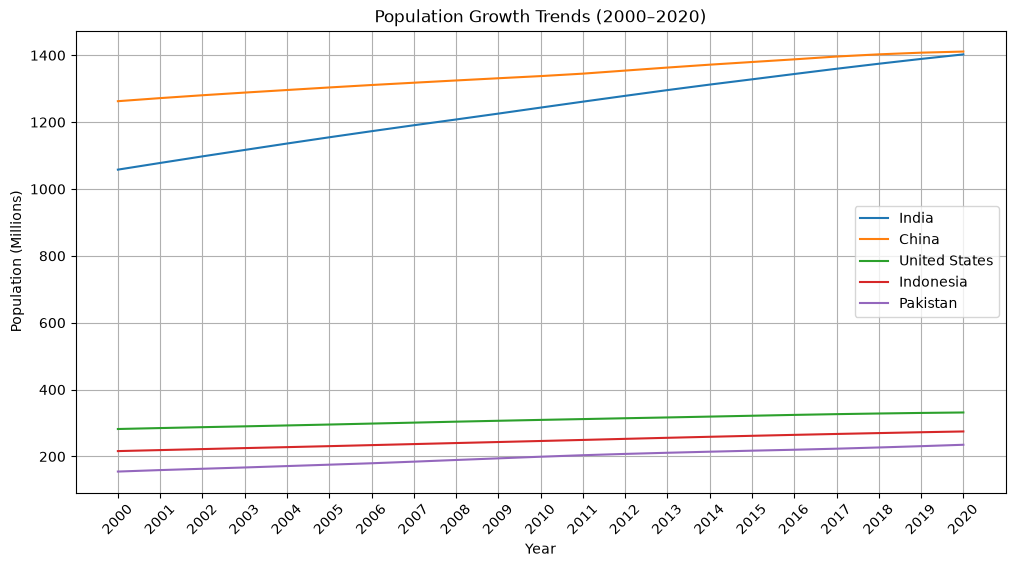

In [20]:

# Plot population growth trends
plt.figure(figsize=(12, 6))

for country in countries:
    data = population_trends[
        population_trends['Country Name'] == country
    ]

    population = data[years].values[0] / 1000000

    plt.plot(years, population, label=country)

plt.title('Population Growth Trends (2000–2020)')
plt.xlabel('Year')
plt.ylabel('Population (Millions)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.show()


### Interpretation: Population Growth Trends (2000–2020)

The line graph shows population growth trends for India, China, the United States, Indonesia and Pakistan between 2000 and 2020.

All five countries experienced population growth during this period. China had the highest population throughout the period, although India gradually narrowed the gap. India's population increased more rapidly than China's, bringing the two countries close to the same population by 2020.

The United States, Indonesia and Pakistan also experienced steady population growth, although their populations remained significantly lower than those of India and China.

Overall, the graph shows that population growth rates differed across the five countries, with India showing particularly strong growth.

In [21]:

# Load GDP data
import os

# Replace with your actual extracted folder path
gdp_folder = r"C:\Users\Tobias\Downloads\API_NY.GDP.MKTP.CD_DS2_en_csv_v2_512"

# Find the GDP CSV file
gdp_file = [f for f in os.listdir(gdp_folder)
            if f.startswith("API_NY.GDP.MKTP.CD")
            and f.endswith(".csv")][0]

# Read the GDP dataset
gdp_data = pd.read_csv(
    os.path.join(gdp_folder, gdp_file),
    skiprows=4
)

# Display first 5 rows
gdp_data.head()


,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,Unnamed: 70
0,Aruba,ABW,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,3.092428e+09,3.276188e+09,3.347562e+09,2.461056e+09,2.889305e+09,3.326671e+09,3.746573e+09,4.167588e+09,NaN,NaN
1,Africa Eastern and Southern,AFE,GDP (current US$),NY.GDP.MKTP.CD,2.420573e+10,2.495893e+10,2.707328e+10,3.176919e+10,3.027960e+10,3.380623e+10,...,9.792406e+11,1.021972e+12,1.019354e+12,9.385461e+11,1.113060e+12,1.226461e+12,1.179122e+12,1.252564e+12,1.358694e+12,NaN
2,Afghanistan,AFG,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,1.875346e+10,1.805322e+10,1.879944e+10,1.995593e+10,1.426000e+10,1.449724e+10,1.715223e+10,1.777851e+10,NaN,NaN
3,Africa Western and Central,AFW,GDP (current US$),NY.GDP.MKTP.CD,1.190481e+10,1.270772e+10,1.363059e+10,1.446891e+10,1.580356e+10,1.692088e+10,...,6.942064e+11,7.778058e+11,1.026528e+12,9.636882e+11,1.026670e+12,1.063748e+12,9.384807e+11,7.373670e+11,8.525270e+11,NaN
4,Angola,AGO,GDP (current US$),NY.GDP.MKTP.CD,NaN,NaN,NaN,NaN,NaN,NaN,...,8.562960e+10,9.050606e+10,8.119381e+10,5.851203e+10,7.828392e+10,1.282340e+11,1.060423e+11,1.030805e+11,1.221749e+11,NaN


In [22]:

# Select population data for 2020
pop_2020 = population_data[['Country Name', '2020']]

# Rename population column
pop_2020 = pop_2020.rename(columns={
    '2020': 'Population'
})

# Select GDP data for 2020
gdp_2020 = gdp_data[['Country Name', '2020']]

# Rename GDP column
gdp_2020 = gdp_2020.rename(columns={
    '2020': 'GDP'
})

# Display population data
pop_2020.head()

,Country Name,Population
0,Aruba,108587.0
1,Africa Eastern and Southern,694446100.0
2,Afghanistan,39068979.0
3,Africa Western and Central,473687685.0
4,Angola,33451132.0


In [23]:

# Combine GDP and population datasets
combined_data = pd.merge(
    pop_2020,
    gdp_2020,
    on='Country Name'
)

# Remove rows with missing values
combined_data = combined_data.dropna()

# Display the combined dataset
combined_data.head()

,Country Name,Population,GDP
0,Aruba,108587.0,2.461056e+09
1,Africa Eastern and Southern,694446100.0,9.385461e+11
2,Afghanistan,39068979.0,1.995593e+10
3,Africa Western and Central,473687685.0,9.636882e+11
4,Angola,33451132.0,5.851203e+10


In [24]:

# Keep countries from the original population dataset
country_codes = pop_clean['Country_Code']

# Add country codes to combined data
combined_data = pd.merge(
    combined_data,
    population_data[['Country Name', 'Country Code']],
    on='Country Name'
)

# Keep individual countries
combined_data = combined_data[
    combined_data['Country Code'].isin(country_codes)
]

# Display the results
combined_data.head()

,Country Name,Population,GDP,Country Code
0,Aruba,108587.0,2.461056e+09,ABW
2,Afghanistan,39068979.0,1.995593e+10,AFG
4,Angola,33451132.0,5.851203e+10,AGO
5,Albania,2528480.0,1.524146e+10,ALB
6,Andorra,77380.0,2.891001e+09,AND


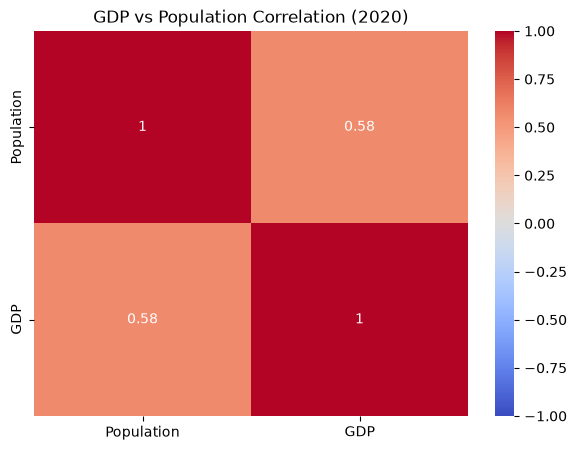

In [25]:

# Calculate correlation
correlation = combined_data[['Population', 'GDP']].corr()

# Create heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('GDP vs Population Correlation (2020)')
plt.show()


### Interpretation: GDP vs Population Correlation (2020)

The correlation heatmap shows a moderate positive relationship between population and GDP in 2020, with a correlation coefficient of 0.58.

This suggests that countries with larger populations generally tend to have higher GDP. However, the relationship is not perfect, indicating that population size alone does not determine a country's economic performance.

Other factors, such as productivity, technology, natural resources and economic development, may also influence GDP.

Overall, the analysis shows that population and GDP are positively related, but correlation does not necessarily imply causation.